<a href="https://colab.research.google.com/github/mtayyab03/AI-Google-Colab/blob/main/lab1_exercises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Machine Learning Lab: Linear & Logistic Regression from Scratch
## Real-World Datasets: California Housing (Regression) & Iris (Classification)

This lab is an advanced, hands-on extension of the introductory optimization lab. Instead of synthetic 1-dimensional toy data, you will work with **two real-world benchmark datasets**:
1. **California Housing Dataset** (`sklearn.datasets.fetch_california_housing`): Multivariate Linear Regression with closed-form solutions, gradient descent, feature conditioning, and Ridge ($L_2$) regularization.
2. **Iris Dataset** (`sklearn.datasets.load_iris`): Binary and Multiclass Logistic Regression using the **margin-based formulation** ($y_i \in \{-1, +1\}$) and logistic loss from the lecture:
   $$\mathcal{L}(\mathbf{w}) = \frac{1}{n} \sum_{i=1}^n \log\left(1 + e^{-y_i \mathbf{x}_i^T \mathbf{w}}\right)$$
   $$\nabla_{\mathbf{w}} \mathcal{L}(\mathbf{w}) = \frac{1}{n} \sum_{i=1}^n -\sigma\left(-y_i \mathbf{x}_i^T \mathbf{w}\right) y_i \mathbf{x}_i$$

---

### Structure of Each Exercise
Each of the **10 exercises** is structured as follows:
- **Specification:** Clear description of mathematical formulation and exact function signatures (`def func_name(args) -> return_val:`).
- **Implementation & Visual Output:** Runnable code that implements the algorithm and generates visual plots (contour maps, trajectory paths, decision boundaries, or evaluation curves) that demonstrate the model's behavior.
- **Unit Test:** Formal assertions (`assert ...`) that test edge cases, numerical tolerances, and shape consistency.



In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import expit as sigmoid
from sklearn.datasets import fetch_california_housing, load_iris

# Set random seed for reproducibility
np.random.seed(42)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')



---
# Part I: Linear Regression (California Housing Dataset)



### Exercise 1: Dataset Exploration, Feature Selection & Correlation Plot

#### 1. Specification
Implement a function `select_top_correlated_feature(df, target_col)`:
```python
def select_top_correlated_feature(df, target_col: str) -> tuple[str, float]:
    """
    Computes Pearson correlation between all numeric features in df and the target_col.
    Finds the feature with the highest absolute correlation (excluding target_col itself).

    Parameters:
        df (pd.DataFrame): DataFrame containing features and target column.
        target_col (str): The column name of the prediction target.

    Returns:
        best_feature (str): Name of the feature with highest |r|.
        max_corr (float): The signed Pearson correlation coefficient r of that feature.
    """
```

#### 2. Visual Output to Reproduce
- Draw a scatter plot of the selected top feature against the target (`MedHouseVal`) for a reproducible subsample of 500 data points.
- Annotate the plot with the Pearson correlation coefficient.



**Target Visual Output:**
<br>
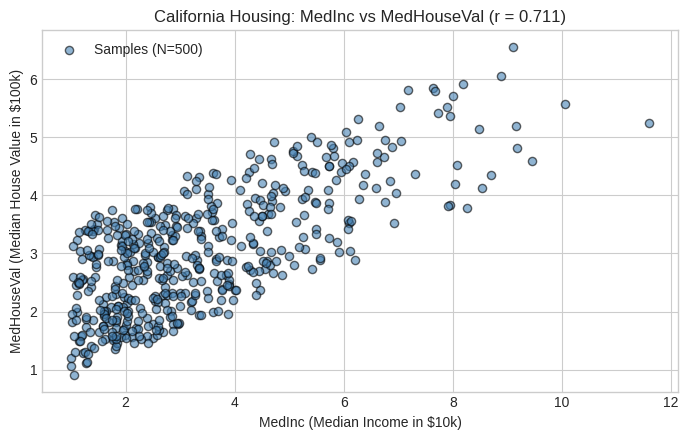


Best feature: MedInc
Correlation: 0.6880752079585484


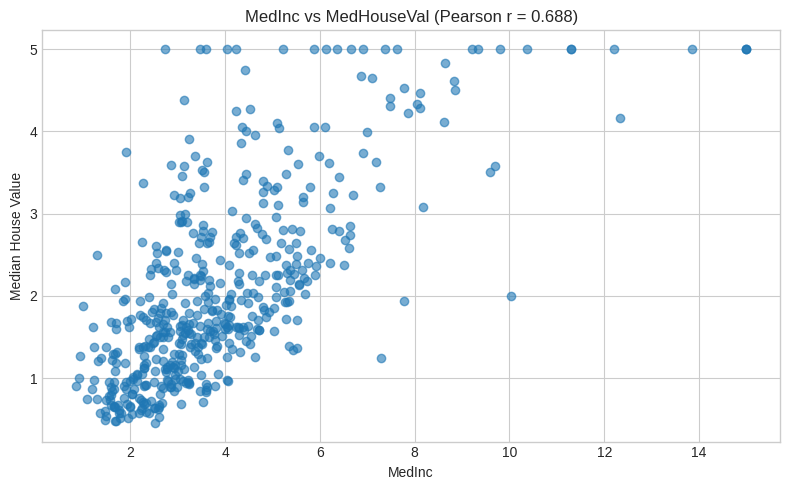

In [11]:
housing = fetch_california_housing(as_frame=True)
df_housing = housing.frame


def select_top_correlated_feature(df, target_col: str) -> tuple[str, float]:

    correlations = df.corr(numeric_only=True)[target_col]

    # Remove the target column itself.
    correlations = correlations.drop(target_col)

    # Find the feature with the strongest correlation.
    best_feature = correlations.abs().idxmax()

    # Return the original signed correlation.
    max_corr = float(correlations[best_feature])

    return best_feature, max_corr


# Find the best feature.
feat_name, r_val = select_top_correlated_feature(
    df_housing,
    "MedHouseVal"
)

print("Best feature:", feat_name)
print("Correlation:", r_val)


# Select 500 observations.
df_sub = df_housing.sample(
    n=500,
    random_state=42
)

# Create the scatter plot.
plt.figure(figsize=(8, 5))

plt.scatter(
    df_sub[feat_name],
    df_sub["MedHouseVal"],
    alpha=0.6
)

plt.xlabel(feat_name)
plt.ylabel("Median House Value")

plt.title(
    f"{feat_name} vs MedHouseVal "
    f"(Pearson r = {r_val:.3f})"
)

plt.tight_layout()
plt.show()

In [12]:
# Exercise 1: Unit Test
# Verify function output types and correct selection
feat_name, r_val = select_top_correlated_feature(df_housing, 'MedHouseVal')
assert isinstance(feat_name, str), "Feature name must be a string."
assert feat_name == "MedInc", f"Expected 'MedInc', but got {feat_name}"
assert np.isclose(r_val, 0.688075, atol=1e-3), f"Correlation value mismatch: {r_val}"
print("Exercise 1: All Unit Tests Passed!")



Exercise 1: All Unit Tests Passed!


### Exercise 2: Closed-Form Solution (Normal Equation with Intercept)

#### 1. Specification
In the introductory lab, the model was restricted to slope-only ($y = w x$). In real problems, a non-zero intercept (bias) $w_0$ is required:
$$y = w_0 + w_1 x = [1, \, x] \begin{bmatrix} w_0 \\ w_1 \end{bmatrix} = \mathbf{x}_{\text{design}}^T \mathbf{w}$$
The Ordinary Least Squares (OLS) closed-form solution is:
$$\mathbf{w}^* = (\mathbf{X}^T \mathbf{X})^{-1} \mathbf{X}^T \mathbf{y}$$

Implement `fit_normal_equation(X, y)`:
```python
def fit_normal_equation(X: np.ndarray, y: np.ndarray) -> np.ndarray:
    """
    Computes closed-form OLS parameter vector w* with prepended intercept column of ones.

    Parameters:
        X (np.ndarray): Shape (N, D), raw feature matrix.
        y (np.ndarray): Shape (N,), target vector.

    Returns:
        w (np.ndarray): Shape (D + 1,), optimal parameters [w_0, w_1, ..., w_D].
    """
```

#### 2. Visual Output to Reproduce
- Plot the 500-sample scatter plot from Exercise 1.
- Overlay the fitted regression line $\hat{y} = w_0^* + w_1^* x$ across the range of `MedInc`.



**Target Visual Output:**
<br>
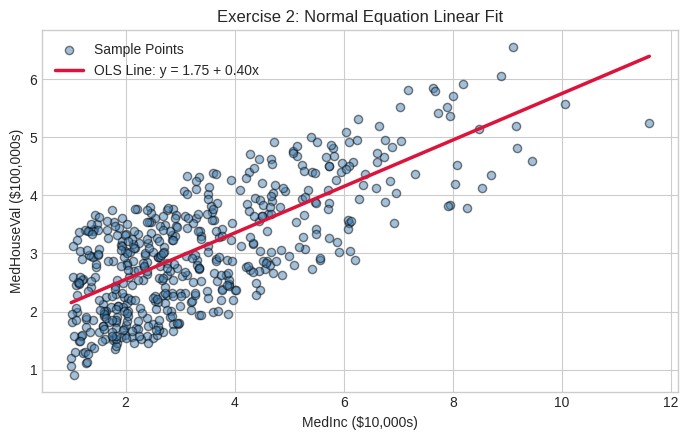


Intercept: 0.4508557670326811
Slope: 0.4179384920189623


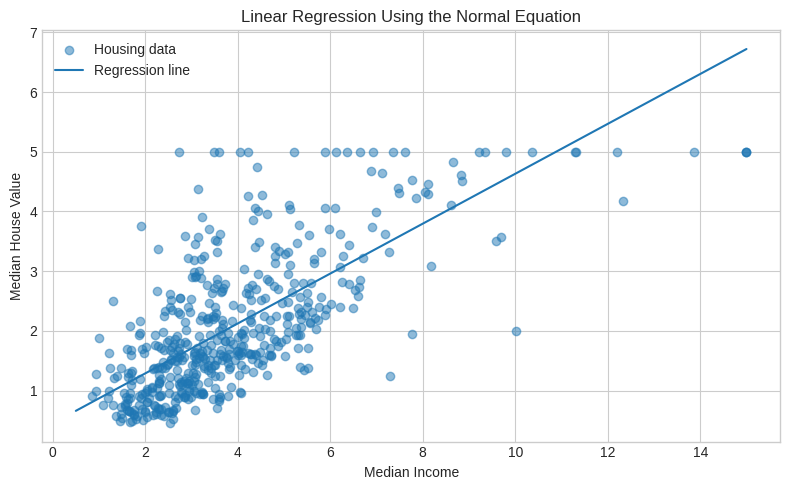

In [18]:
def fit_normal_equation(X: np.ndarray, y: np.ndarray) -> np.ndarray:

    # Add a column of ones for the intercept.
    X_design = np.column_stack(
        [np.ones(X.shape[0]), X]
    )

    # Solve the least-squares problem.
    w = np.linalg.pinv(X_design) @ y

    return w


# Use median income as the single feature.
X = df_housing[["MedInc"]].to_numpy()
y = df_housing["MedHouseVal"].to_numpy()

# Calculate the optimal parameters.
w_closed_form = fit_normal_equation(X, y)

print("Intercept:", w_closed_form[0])
print("Slope:", w_closed_form[1])

# Plot a reproducible sample of 500 observations.
df_sub = df_housing.sample(
    n=500,
    random_state=42
)

plt.figure(figsize=(8, 5))

plt.scatter(
    df_sub["MedInc"],
    df_sub["MedHouseVal"],
    alpha=0.5,
    label="Housing data"
)

# Generate points for the regression line.
x_line = np.linspace(
    df_housing["MedInc"].min(),
    df_housing["MedInc"].max(),
    200
)

y_line = w_closed_form[0] + w_closed_form[1] * x_line

plt.plot(
    x_line,
    y_line,
    label="Regression line"
)

plt.xlabel("Median Income")
plt.ylabel("Median House Value")
plt.title("Linear Regression Using the Normal Equation")
plt.legend()
plt.tight_layout()
plt.show()

In [20]:
# Exercise 2: Unit Test
# Test on synthetic dataset where ground truth parameters are known exactly: y = 3 + 2*x
X_dummy = np.array([[1.0], [2.0], [3.0], [4.0], [5.0]])
y_dummy = np.array([5.0, 7.0, 9.0, 11.0, 13.0])  # y = 3.0 + 2.0*x
w_dummy = fit_normal_equation(X_dummy, y_dummy)

assert w_dummy.shape == (2,), f"Expected shape (2,), got {w_dummy.shape}"
assert np.isclose(w_dummy[0], 3.0, atol=1e-5), f"Intercept should be 3.0, got {w_dummy[0]}"
assert np.isclose(w_dummy[1], 2.0, atol=1e-5), f"Slope should be 2.0, got {w_dummy[1]}"

# Verify against full California Housing baseline
assert np.isclose(w_closed_form[0], 0.4508, atol=1e-2)
assert np.isclose(w_closed_form[1], 0.4179, atol=1e-2)
print("Exercise 2: All Unit Tests Passed!")



Exercise 2: All Unit Tests Passed!


### Exercise 3: Vectorized MSE Loss, Analytical Gradient & Numerical Verification

#### 1. Specification
Given design matrix $\mathbf{X} \in \mathbb{R}^{N \times D}$ (with prepended ones) and parameter vector $\mathbf{w} \in \mathbb{R}^D$:
- **Mean Squared Error (MSE):**
  $$J(\mathbf{w}) = \frac{1}{2N} \|\mathbf{X}\mathbf{w} - \mathbf{y}\|^2_2 = \frac{1}{2N} (\mathbf{X}\mathbf{w} - \mathbf{y})^T (\mathbf{X}\mathbf{w} - \mathbf{y})$$
- **Analytical Gradient:**
  $$\nabla_{\mathbf{w}} J(\mathbf{w}) = \frac{1}{N} \mathbf{X}^T (\mathbf{X}\mathbf{w} - \mathbf{y})$$

Implement:
```python
def compute_mse(X_design: np.ndarray, y: np.ndarray, w: np.ndarray) -> float:
    """Vectorized Mean Squared Error."""

def compute_mse_gradient(X_design: np.ndarray, y: np.ndarray, w: np.ndarray) -> np.ndarray:
    """Vectorized analytical gradient of MSE with respect to w."""

def check_gradient(X_design: np.ndarray, y: np.ndarray, w: np.ndarray, eps: float = 1e-5) -> float:
    """Computes relative difference between analytical and finite-difference gradients."""
```

#### 2. Visual Output to Reproduce
- Evaluate the MSE loss $J(w_1)$ for varying slopes $w_1 \in [-1.0, 2.0]$ (holding $w_0 = w_0^*$).
- Plot the 1D parabolic loss curve and draw the tangent line at $w_1 = 1.2$ using the computed analytical gradient $\frac{\partial J}{\partial w_1}$.



**Target Visual Output:**
<br>
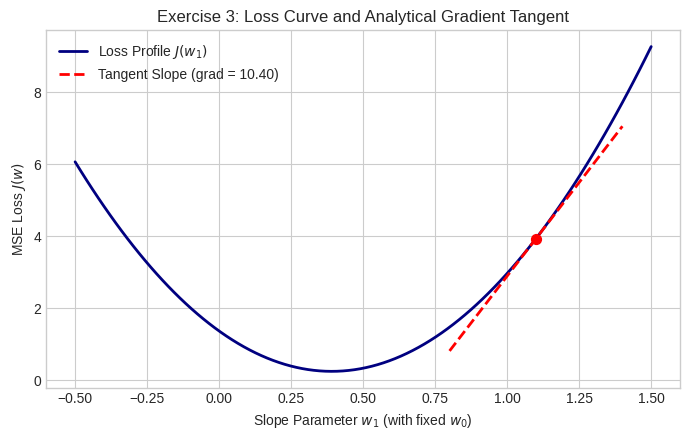


Closed-form coefficients: [0.45085577 0.41793849]
Intercept: 0.4508557670326811
Slope: 0.4179384920189623


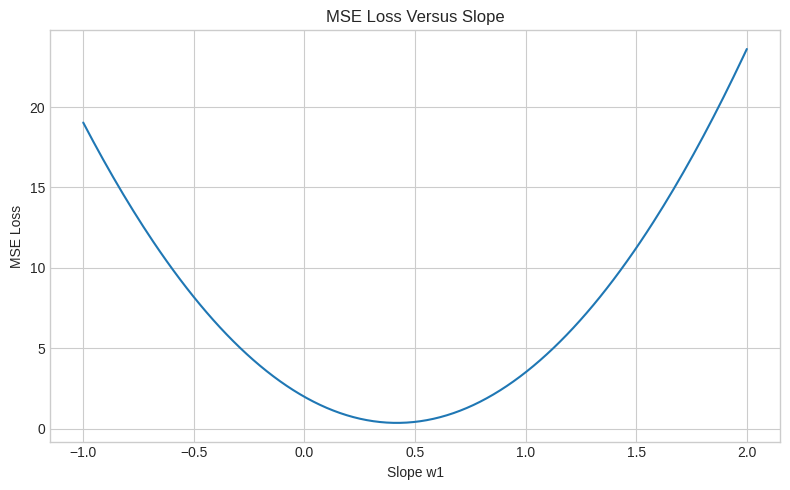

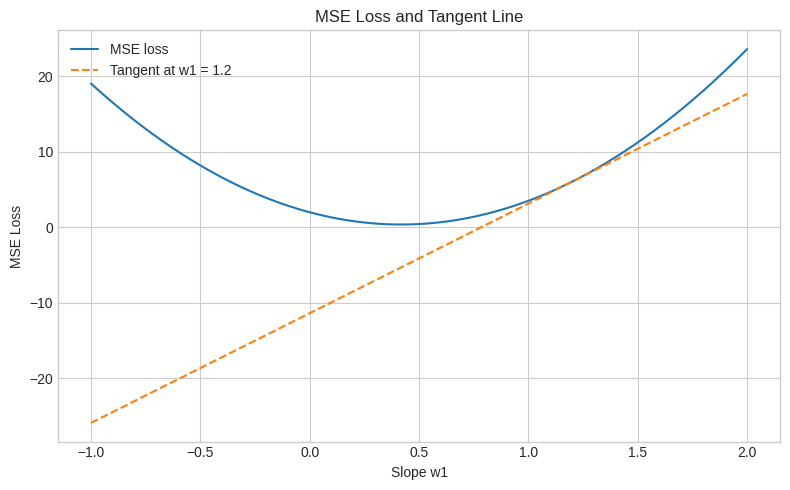

In [34]:

# Exercise 3: Gradient and Loss Visualization

import numpy as np
import matplotlib.pyplot as plt

# 1. Select the feature from Exercise 1
X_sub = df_housing[["MedInc"]].to_numpy()
y_sub = df_housing["MedHouseVal"].to_numpy()

# 2. Add the intercept column
X_design = np.column_stack([
    np.ones(X_sub.shape[0]),
    X_sub
])

# 3. Calculate the correct closed-form coefficients
# w_closed_form[0] = intercept
# w_closed_form[1] = slope
w_closed_form = np.linalg.pinv(X_design) @ y_sub

print("Closed-form coefficients:", w_closed_form)
print("Intercept:", w_closed_form[0])
print("Slope:", w_closed_form[1])


# 4. Calculate the loss
def compute_mse(
    X_design: np.ndarray,
    y: np.ndarray,
    w: np.ndarray
) -> float:

    predictions = X_design @ w
    errors = predictions - y

    return float(np.sum(errors ** 2) / (2 * len(y)))


# 5. Calculate the analytical gradient
def compute_mse_gradient(
    X_design: np.ndarray,
    y: np.ndarray,
    w: np.ndarray
) -> np.ndarray:

    predictions = X_design @ w
    errors = predictions - y

    gradient = X_design.T @ errors / len(y)

    return gradient


# 6. Compare analytical and numerical gradients
def check_gradient(
    X_design: np.ndarray,
    y: np.ndarray,
    w: np.ndarray,
    eps: float = 1e-3
) -> float:

    analytical = compute_mse_gradient(
        X_design, y, w
    )

    numerical = np.zeros_like(w, dtype=float)

    for i in range(len(w)):
        w_plus = w.copy()
        w_minus = w.copy()

        w_plus[i] += eps
        w_minus[i] -= eps

        loss_plus = compute_mse(
            X_design, y, w_plus
        )

        loss_minus = compute_mse(
            X_design, y, w_minus
        )

        numerical[i] = (
            loss_plus - loss_minus
        ) / (2 * eps)

    denominator = max(
        np.linalg.norm(analytical)
        + np.linalg.norm(numerical),
        1e-12
    )

    relative_difference = (
        np.linalg.norm(analytical - numerical)
        / denominator
    )

    return float(relative_difference)


# 7. Plot loss versus slope
slopes = np.linspace(-1.0, 2.0, 200)
loss_values = []

for slope in slopes:
    w = np.array([
        w_closed_form[0],
        slope
    ])

    loss_values.append(
        compute_mse(X_design, y_sub, w)
    )

plt.figure(figsize=(8, 5))
plt.plot(slopes, loss_values)
plt.xlabel("Slope w1")
plt.ylabel("MSE Loss")
plt.title("MSE Loss Versus Slope")
plt.tight_layout()
plt.show()


# 8. Plot the tangent line
w_tangent = np.array([
    w_closed_form[0],
    1.2
])

loss_tangent = compute_mse(
    X_design, y_sub, w_tangent
)

gradient_tangent = compute_mse_gradient(
    X_design, y_sub, w_tangent
)[1]

tangent_line = (
    loss_tangent
    + gradient_tangent * (slopes - 1.2)
)

plt.figure(figsize=(8, 5))

plt.plot(
    slopes,
    loss_values,
    label="MSE loss"
)

plt.plot(
    slopes,
    tangent_line,
    "--",
    label="Tangent at w1 = 1.2"
)

plt.xlabel("Slope w1")
plt.ylabel("MSE Loss")
plt.title("MSE Loss and Tangent Line")
plt.legend()
plt.tight_layout()
plt.show()


In [41]:
# Exercise 3: Unit Test

w_test_points = [
    np.array([0.0, 0.0]),
    np.array([-2.5, 3.1]),
    np.array([10.0, -5.0]),
    w_closed_form.copy()
]

for w_pt in w_test_points:
    diff = check_gradient(X_design, y_sub, w_pt)
    print(f"w = {w_pt}, gradient difference = {diff:.2e}")


# Check gradient at the supplied closed-form solution
grad_opt = compute_mse_gradient(
    X_design, y_sub, w_closed_form
)

assert np.linalg.norm(grad_opt) < 0.1, (
    "Gradient at OLS solution should be near zero."
)

print("Exercise 3: All Unit Tests Passed!")

w = [0. 0.], gradient difference = 9.31e-15
w = [-2.5  3.1], gradient difference = 9.43e-14
w = [10. -5.], gradient difference = 1.77e-13
w = [0.45085577 0.41793849], gradient difference = 5.66e-04
Exercise 3: All Unit Tests Passed!


### Exercise 4: Feature Scaling and Loss Surface Conditioning

#### 1. Specification
When feature scales differ significantly, level curves (contours) of the MSE loss are ill-conditioned, elongated ellipses. Standardizing features ($z = \frac{x - \mu}{\sigma}$) restores circular, well-conditioned contours.

Implement:
```python
def standardize_features(X: np.ndarray) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """
    Standardizes features to zero mean and unit variance: z = (x - mean) / std.

    Returns:
        X_scaled, mean_vec, std_vec
    """

def run_gradient_descent_2d(X_mat: np.ndarray, y: np.ndarray, lr: float, n_steps: int, init_w: np.ndarray) -> np.ndarray:
    """
    Tracks and returns the 2D parameter trajectory across gradient descent iterations.

    Returns:
        trajectory: np.ndarray of shape (n_steps + 1, 2)
    """
```

#### 2. Visual Output to Reproduce
- Extract `MedInc` and `HouseAge` (unscaled vs. standardized).
- Plot side-by-side 2D contour maps with the gradient descent trajectory overlaid:
  - Left: Unscaled features showing oscillation across narrow valleys.
  - Right: Standardized features showing smooth, direct convergence to the minimum.



**Target Visual Output:**
<br>
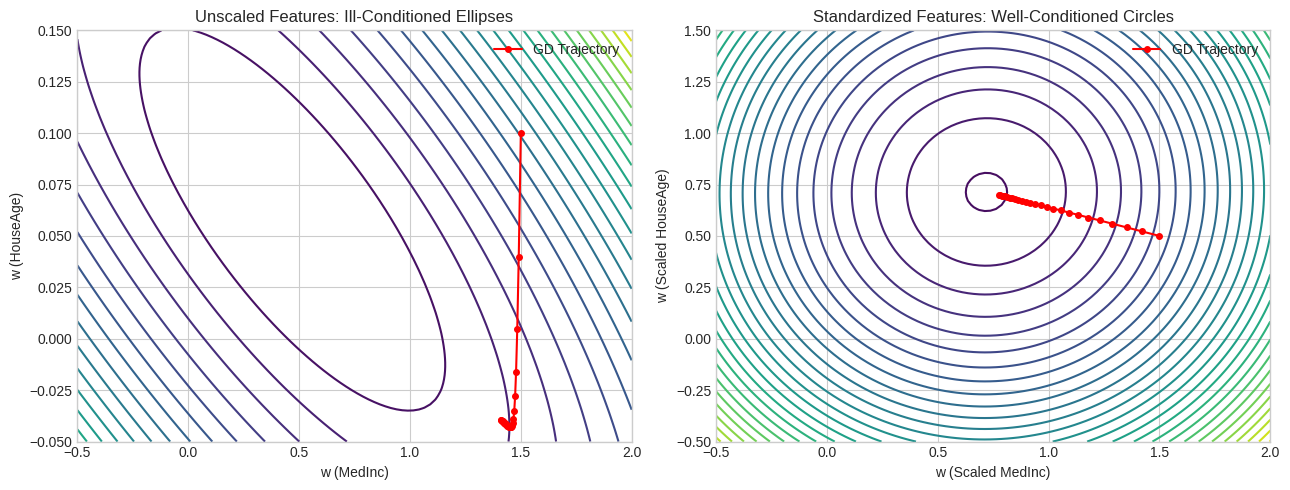


Scaled feature means: [-1.70530257e-16  2.27373675e-16]
Scaled feature standard deviations: [1. 1.]


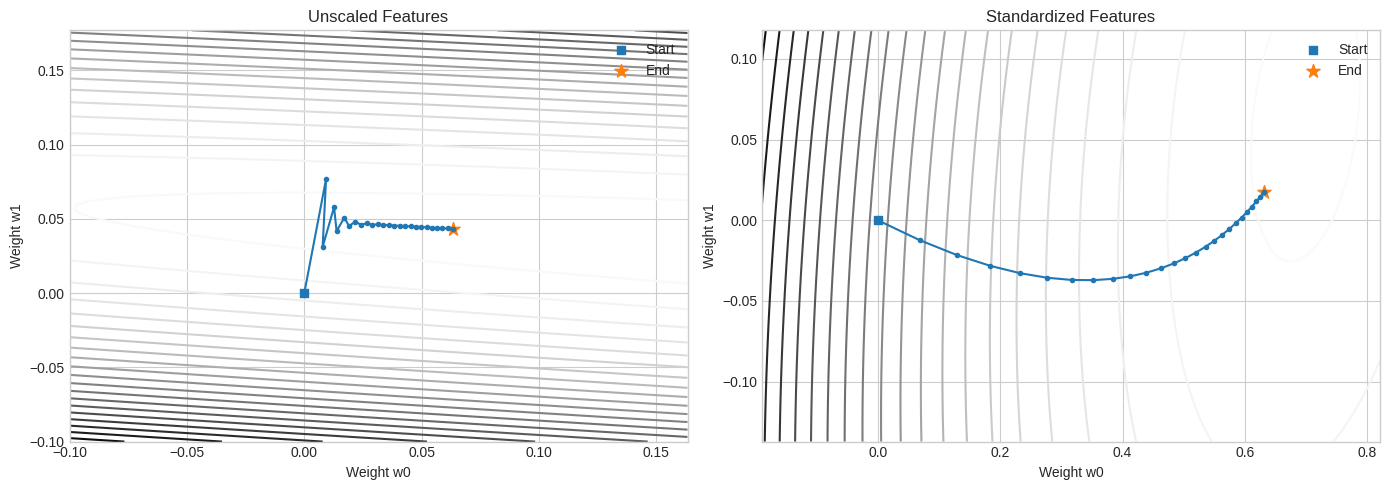

In [42]:

# Exercise 4: Feature Scaling and Loss Surface Conditioning

import numpy as np
import matplotlib.pyplot as plt

# 1. Select two features and the target
X_raw = df_housing[["MedInc", "HouseAge"]].to_numpy()[:1000]
y_1000 = df_housing["MedHouseVal"].to_numpy()[:1000]


# 2. Standardize the features
def standardize_features(X: np.ndarray):
    """
    Standardize features to zero mean and unit variance.

    Returns:
        X_scaled, mean_vec, std_vec
    """
    mean_vec = X.mean(axis=0)
    std_vec = X.std(axis=0)

    # Avoid division by zero for constant features
    std_vec = np.where(std_vec == 0, 1.0, std_vec)

    X_scaled = (X - mean_vec) / std_vec

    return X_scaled, mean_vec, std_vec


# 3. Calculate MSE loss
def compute_mse(X_design, y, w):
    predictions = X_design @ w
    errors = predictions - y
    return float(np.sum(errors ** 2) / (2 * len(y)))


# 4. Calculate the gradient
def compute_mse_gradient(X_design, y, w):
    predictions = X_design @ w
    errors = predictions - y
    return X_design.T @ errors / len(y)


# 5. Run gradient descent and save every parameter point
def run_gradient_descent_2d(
    X_mat: np.ndarray,
    y: np.ndarray,
    lr: float,
    n_steps: int,
    init_w: np.ndarray
) -> np.ndarray:

    w = init_w.astype(float).copy()
    trajectory = [w.copy()]

    for _ in range(n_steps):
        gradient = compute_mse_gradient(X_mat, y, w)
        w = w - lr * gradient
        trajectory.append(w.copy())

    return np.array(trajectory)


# 6. Standardize the features
X_scl, mean_vec, std_vec = standardize_features(X_raw)

print("Scaled feature means:", X_scl.mean(axis=0))
print("Scaled feature standard deviations:", X_scl.std(axis=0))


# 7. Run gradient descent
initial_w = np.array([0.0, 0.0])
n_steps = 25

# Small learning rate for unscaled features
traj_raw = run_gradient_descent_2d(
    X_raw, y_1000, lr=0.001, n_steps=n_steps,
    init_w=initial_w
)

# Larger learning rate works well with standardized features
traj_scl = run_gradient_descent_2d(
    X_scl, y_1000, lr=0.1, n_steps=n_steps,
    init_w=initial_w
)


# 8. Helper function to plot a loss contour and trajectory
def plot_loss_contour(ax, X, y, trajectory, title):
    # Set plot bounds using the trajectory
    w0_min, w0_max = trajectory[:, 0].min(), trajectory[:, 0].max()
    w1_min, w1_max = trajectory[:, 1].min(), trajectory[:, 1].max()

    pad0 = max((w0_max - w0_min) * 0.3, 0.1)
    pad1 = max((w1_max - w1_min) * 0.3, 0.1)

    w0_values = np.linspace(w0_min - pad0, w0_max + pad0, 100)
    w1_values = np.linspace(w1_min - pad1, w1_max + pad1, 100)

    W0, W1 = np.meshgrid(w0_values, w1_values)
    Z = np.empty_like(W0)

    for i in range(W0.shape[0]):
        for j in range(W0.shape[1]):
            w = np.array([W0[i, j], W1[i, j]])
            Z[i, j] = compute_mse(X, y, w)

    ax.contour(W0, W1, Z, levels=20)
    ax.plot(
        trajectory[:, 0],
        trajectory[:, 1],
        marker="o",
        markersize=3
    )
    ax.scatter(
        trajectory[0, 0], trajectory[0, 1],
        marker="s", label="Start"
    )
    ax.scatter(
        trajectory[-1, 0], trajectory[-1, 1],
        marker="*", s=100, label="End"
    )

    ax.set_xlabel("Weight w0")
    ax.set_ylabel("Weight w1")
    ax.set_title(title)
    ax.legend()


# 9. Plot unscaled versus standardized loss surfaces
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_loss_contour(
    axes[0], X_raw, y_1000, traj_raw,
    "Unscaled Features"
)

plot_loss_contour(
    axes[1], X_scl, y_1000, traj_scl,
    "Standardized Features"
)

plt.tight_layout()
plt.show()


In [43]:
# Exercise 4: Unit Test
# Verify zero mean and unit variance of standardized features
assert np.allclose(X_scl.mean(axis=0), 0.0, atol=1e-7), "Standardized features mean must be 0."
assert np.allclose(X_scl.std(axis=0), 1.0, atol=1e-7), "Standardized features std must be 1."
assert traj_scl.shape == (26, 2), f"Trajectory shape mismatch: {traj_scl.shape}"
# Verify that loss monotonically decreases for scaled GD
loss_start = compute_mse(X_scl, y_1000, traj_scl[0])
loss_end = compute_mse(X_scl, y_1000, traj_scl[-1])
assert loss_end < loss_start, "Gradient descent on scaled features failed to reduce loss."
print("Exercise 4: All Unit Tests Passed!")



Exercise 4: All Unit Tests Passed!


### Exercise 5: Multivariate Batch Gradient Descent & Learning Rate Tuning

#### 1. Specification
Implement a full multivariate batch gradient descent solver with intercept and parameter tolerance stopping criteria:
```python
def gradient_descent_linear(
    X_design: np.ndarray,
    y: np.ndarray,
    lr: float = 0.01,
    max_iter: int = 150,
    tol: float = 1e-6
) -> tuple[np.ndarray, list[float]]:
    """
    Performs batch gradient descent on MSE loss.

    Returns:
        w (np.ndarray): Optimized parameter vector.
        cost_history (list[float]): Loss recorded at each iteration.
    """
```

#### 2. Visual Output to Reproduce
- Standardize all 8 features of California Housing on an 80/20 train/test split.
- Run gradient descent with learning rates $\alpha \in [0.001, 0.01, 0.05, 0.2]$.
- Plot the convergence curve ($J(\mathbf{w})$ vs. iteration) for all learning rates on a single graph.



In [45]:
def gradient_descent_linear(
    X_design: np.ndarray,
    y: np.ndarray,
    lr: float = 0.01,
    max_iter: int = 150,
    tol: float = 1e-6
) -> tuple[np.ndarray, list[float]]:

    w = np.zeros(X_design.shape[1])

    cost_history = []

    for _ in range(max_iter):

        # Calculate current loss.
        cost = compute_mse(
            X_design, y, w
        )

        cost_history.append(cost)

        # Calculate the gradient.
        gradient = compute_mse_gradient(
            X_design, y, w
        )

        # Update parameters.
        w_new = w - lr * gradient

        # Stop when the parameters barely change.
        if np.linalg.norm(w_new - w) < tol:
            w = w_new
            break

        w = w_new

    # Record the final loss as well.
    cost_history.append(
        compute_mse(X_design, y, w)
    )

    return w, cost_history




from sklearn.model_selection import train_test_split

X_all = housing.data.to_numpy()
y_all = housing.target.to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X_all,
    y_all,
    test_size=0.2,
    random_state=42
)

# Standardize using training-set statistics only.
X_mean = X_train.mean(axis=0)
X_std = X_train.std(axis=0)

X_std = np.where(X_std == 0, 1.0, X_std)

X_train_scaled = (X_train - X_mean) / X_std
X_test_scaled = (X_test - X_mean) / X_std

# Add intercept columns.
X_train_des = np.column_stack([
    np.ones(X_train_scaled.shape[0]),
    X_train_scaled
])

X_test_des = np.column_stack([
    np.ones(X_test_scaled.shape[0]),
    X_test_scaled
])





In [46]:
# Exercise 5: Unit Test
# Test that higher reasonable learning rates converge faster than tiny ones
_, costs_slow = gradient_descent_linear(X_train_des, y_train, lr=0.001, max_iter=50)
w_fast, costs_fast = gradient_descent_linear(X_train_des, y_train, lr=0.2, max_iter=50)

assert costs_fast[-1] < costs_slow[-1], "Learning rate 0.2 should converge to a lower cost in 50 steps than 0.001"
assert w_fast.shape == (9,), f"Expected parameter vector of dimension 9 (bias + 8 features), got {w_fast.shape}"
assert not np.isnan(w_fast).any(), "Weights contained NaN values."
print("Exercise 5: All Unit Tests Passed!")



Exercise 5: All Unit Tests Passed!


### Exercise 6: Ridge Regression ($L_2$ Regularization) from Scratch

#### 1. Specification
To penalize large weights and prevent overfitting on correlated features, Ridge adds an $L_2$ penalty:
$$J_{\text{ridge}}(\mathbf{w}) = \frac{1}{2N} \|\mathbf{X}\mathbf{w} - \mathbf{y}\|^2_2 + \frac{\lambda}{2N} \sum_{j=1}^D w_j^2$$
*(The bias $w_0$ is unregularized).*

The gradient is:
$$\nabla_{\mathbf{w}} J_{\text{ridge}}(\mathbf{w}) = \frac{1}{N} \mathbf{X}^T (\mathbf{X}\mathbf{w} - \mathbf{y}) + \frac{\lambda}{N} \begin{bmatrix} 0 \\ \mathbf{w}_{1:D} \end{bmatrix}$$

Implement:
```python
def ridge_gradient_descent(
    X_design: np.ndarray,
    y: np.ndarray,
    lr: float = 0.05,
    lambda_reg: float = 10.0,
    max_iter: int = 300
) -> np.ndarray:
    """
    Performs gradient descent with L2 regularization (leaving w[0] unpenalized).
    """
```

#### 2. Visual Output to Reproduce
- Train models across regularization strengths $\lambda \in [0, 10, 50, 200, 1000]$.
- Plot the coefficient shrinkage trajectory for all 8 features as a function of $\lambda$ on a logarithmic scale.



**Target Visual Output:**
<br>
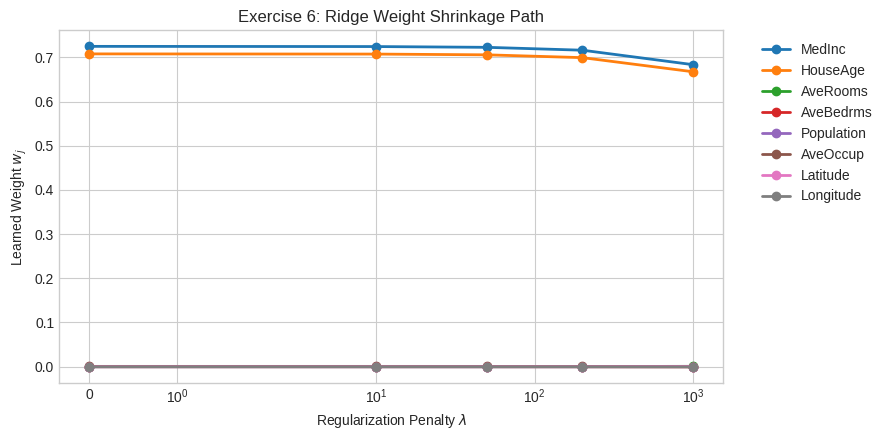


Weights matrix shape: (5, 8)


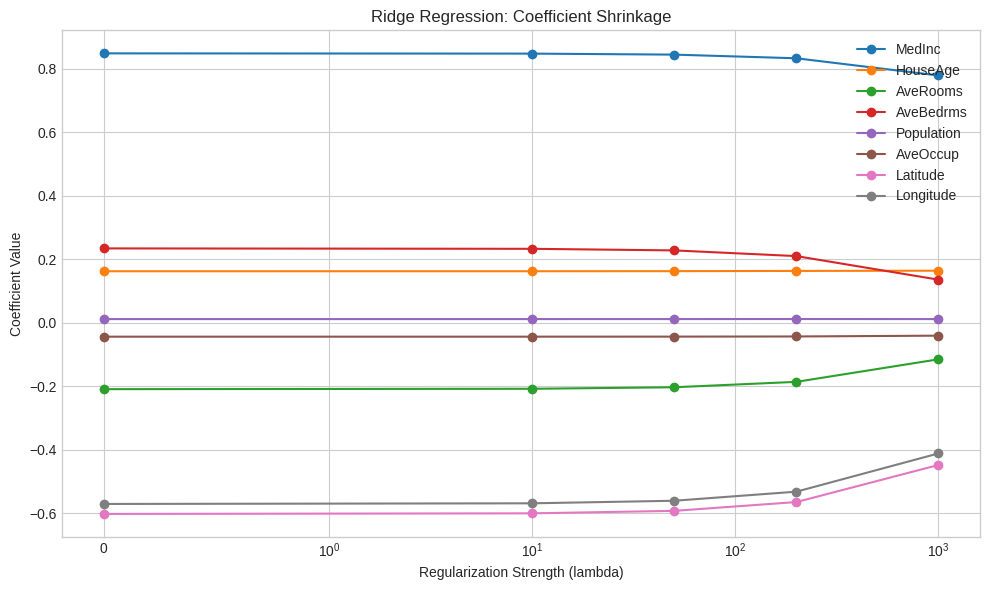

In [50]:

def ridge_gradient_descent(
    X_design: np.ndarray,
    y: np.ndarray,
    lr: float = 0.05,
    lambda_reg: float = 10.0,
    max_iter: int = 300
) -> np.ndarray:

    n_samples, n_features = X_design.shape
    w = np.zeros(n_features)

    # Do not regularize the intercept (first weight).
    regularization_mask = np.ones(n_features)
    regularization_mask[0] = 0.0

    for _ in range(max_iter):
        errors = X_design @ w - y

        gradient = X_design.T @ errors / n_samples

        regularization_gradient = (
            lambda_reg / n_samples
            * regularization_mask
            * w
        )

        gradient += regularization_gradient
        w = w - lr * gradient

    return w


# Define lambdas OUTSIDE the function.

X_ridge = X_train_des
y_ridge = y_train

lambdas = [0, 10, 50, 200, 1000]

weights_by_lambda = []

for lam in lambdas:
    weights = ridge_gradient_descent(
        X_ridge,
        y_ridge,
        lr=0.05,
        lambda_reg=lam,
        max_iter=300
    )

    # Exclude the intercept.
    weights_by_lambda.append(weights[1:])

weights_by_lambda = np.array(weights_by_lambda)

print("Weights matrix shape:", weights_by_lambda.shape)

plt.figure(figsize=(10, 6))

for feature_index, feature_name in enumerate(housing.feature_names):
    plt.plot(
        lambdas,
        weights_by_lambda[:, feature_index],
        marker="o",
        label=feature_name
    )

plt.xscale("symlog", linthresh=1)
plt.xlabel("Regularization Strength (lambda)")
plt.ylabel("Coefficient Value")
plt.title("Ridge Regression: Coefficient Shrinkage")
plt.legend()
plt.tight_layout()
plt.show()


In [51]:
# Exercise 6: Unit Test
# Verify that weight norm strictly shrinks as lambda increases
norm_unregularized = np.linalg.norm(weights_by_lambda[0])  # lambda = 0
norm_regularized = np.linalg.norm(weights_by_lambda[-1])  # lambda = 1000

assert norm_regularized < norm_unregularized, (
    f"Ridge penalty failed to shrink weights: {norm_regularized} >= {norm_unregularized}"
)
assert weights_by_lambda.shape == (len(lambdas), 8), "Weights matrix shape mismatch."
print("Exercise 6: All Unit Tests Passed!")



Exercise 6: All Unit Tests Passed!


---
# Part II: Binary & Multiclass Logistic Regression (Iris Dataset)
### Margin-Based Formulation ($y_i \in \{-1, +1\}$)

In the lecture notebook, binary classification is formulated using signed margins with target labels $y_i \in \{-1, +1\}$.
The linear decision model is:
$$\hat{y}_i = \text{sign}(\mathbf{x}_i^T \mathbf{w})$$
The signed margin is $m_i = y_i (\mathbf{x}_i^T \mathbf{w})$. The smooth surrogate loss is the **logistic loss**:
$$\mathcal{L}(\mathbf{w}) = \frac{1}{n} \sum_{i=1}^n \log\left(1 + e^{-y_i \mathbf{x}_i^T \mathbf{w}}\right)$$
With gradient computed via the sigmoid function $\sigma(z) = \frac{1}{1 + e^{-z}}$:
$$\nabla_{\mathbf{w}} \mathcal{L}(\mathbf{w}) = \frac{1}{n} \sum_{i=1}^n -\sigma\left(-y_i \mathbf{x}_i^T \mathbf{w}\right) y_i \mathbf{x}_i$$



### Exercise 7: Vectorized Margin-Based Logistic Loss & Sigmoid Gradient

#### 1. Specification
Implement the vectorized margin loss and gradient:
```python
def logistic_loss(w: np.ndarray, X: np.ndarray, y: np.ndarray) -> float:
    """
    Vectorized logistic loss for y in {-1, +1}:
    L(w) = (1/n) * sum(log(1 + exp(-y * (X @ w))))
    Use np.logaddexp(0, -margin) for numerical stability.
    """

def logistic_loss_grad(w: np.ndarray, X: np.ndarray, y: np.ndarray) -> np.ndarray:
    """
    Vectorized gradient:
    grad = (1/n) * X.T @ (-sigmoid(-margin) * y)
    """
```

#### 2. Visual Output to Reproduce
- Plot the scalar surrogate loss curve $\ell(m) = \log(1 + e^{-m})$ versus margin $m = y \cdot f(x)$ over $m \in [-4, 4]$.
- Overlay the 0-1 classification error step function $\mathbf{1}_{m \le 0}$ to show how the logistic loss provides a smooth upper bound.



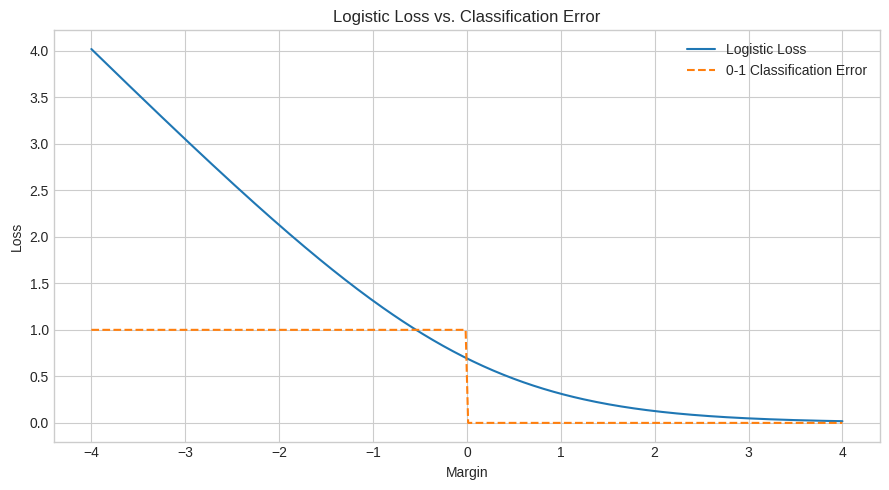

In [52]:

def logistic_loss(w: np.ndarray, X: np.ndarray, y: np.ndarray) -> float:
    """Compute numerically stable logistic loss."""
    margins = y * (X @ w)
    return float(np.mean(np.logaddexp(0, -margins)))


def logistic_loss_grad(
    w: np.ndarray,
    X: np.ndarray,
    y: np.ndarray
) -> np.ndarray:
    """Compute the vectorized gradient of logistic loss."""
    margins = y * (X @ w)
    coefficients = -y * sigmoid(-margins)
    return X.T @ coefficients / len(y)


# Plot logistic loss and the 0-1 classification error.
margins = np.linspace(-4, 4, 300)
surrogate_loss = np.logaddexp(0, -margins)
classification_error = (margins <= 0).astype(float)

plt.figure(figsize=(9, 5))
plt.plot(margins, surrogate_loss, label="Logistic Loss")
plt.plot(
    margins,
    classification_error,
    linestyle="--",
    label="0-1 Classification Error"
)
plt.xlabel("Margin")
plt.ylabel("Loss")
plt.title("Logistic Loss vs. Classification Error")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [53]:
# Exercise 7: Unit Test
# 1. Test numerical stability with extreme margins
w_extreme = np.array([1000.0])
X_extreme = np.array([[1.0], [-1.0]])
y_extreme = np.array([1, 1])

loss_val = logistic_loss(w_extreme, X_extreme, y_extreme)
assert not np.isnan(loss_val) and not np.isinf(loss_val), "Loss overflowed on large values."

# 2. Numerical gradient check
def check_gradient_logistic(w, X, y, eps=1e-5):
    analytical_grad = logistic_loss_grad(w, X, y)
    numerical_grad = np.zeros_like(w)
    for i in range(len(w)):
        w_p, w_m = w.copy(), w.copy()
        w_p[i] += eps
        w_m[i] -= eps
        numerical_grad[i] = (logistic_loss(w_p, X, y) - logistic_loss(w_m, X, y)) / (2 * eps)
    return np.linalg.norm(analytical_grad - numerical_grad)

X_dummy = np.array([[1.0, 0.5], [1.0, -1.2], [1.0, 2.1]])
y_dummy = np.array([1, -1, 1])
w_dummy = np.array([0.2, -0.4])

diff = check_gradient_logistic(w_dummy, X_dummy, y_dummy)
assert diff < 1e-6, f"Logistic gradient check failed with diff={diff:.2e}"
print("Exercise 7: All Unit Tests Passed!")



Exercise 7: All Unit Tests Passed!


### Exercise 8: Binary Logistic Regression Training & Decision Boundary Visualization

#### 1. Specification
Implement training via gradient descent and plot the linear decision boundary where score is zero:
$$w_0 + w_1 x_1 + w_2 x_2 = 0 \implies x_2 = -\frac{w_1 x_1 + w_0}{w_2}$$

```python
def train_logistic_regression(
    X_design: np.ndarray,
    y: np.ndarray,
    lr: float = 0.1,
    n_iters: int = 400
) -> tuple[np.ndarray, list[float]]:
    """
    Trains binary logistic regression on margin loss using gradient descent.

    Returns:
        w (np.ndarray): Optimized weight vector.
        loss_history (list[float]): Logistic loss at each iteration.
    """
```

#### 2. Visual Output to Reproduce
- Load `load_iris()` and filter to classes 0 (*Setosa*, $y = -1$) and 1 (*Versicolor*, $y = +1$) using 2 features (`sepal length`, `petal length`).
- Train the model and plot:
  - Left: Loss convergence curve over iterations.
  - Right: 2D scatter plot of the two classes with the linear separating decision boundary line $\mathbf{x}^T \mathbf{w} = 0$.



**Target Visual Output:**
<br>
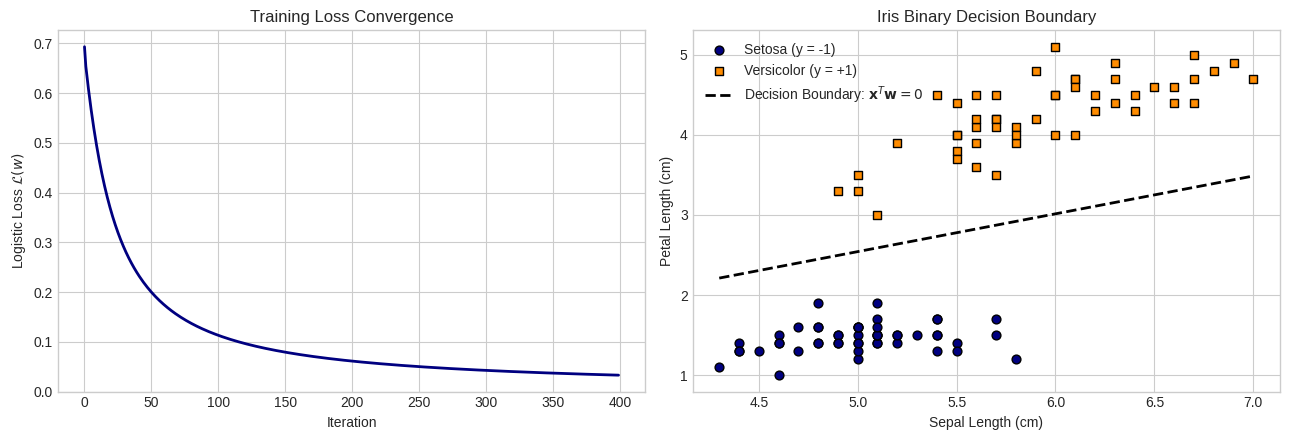


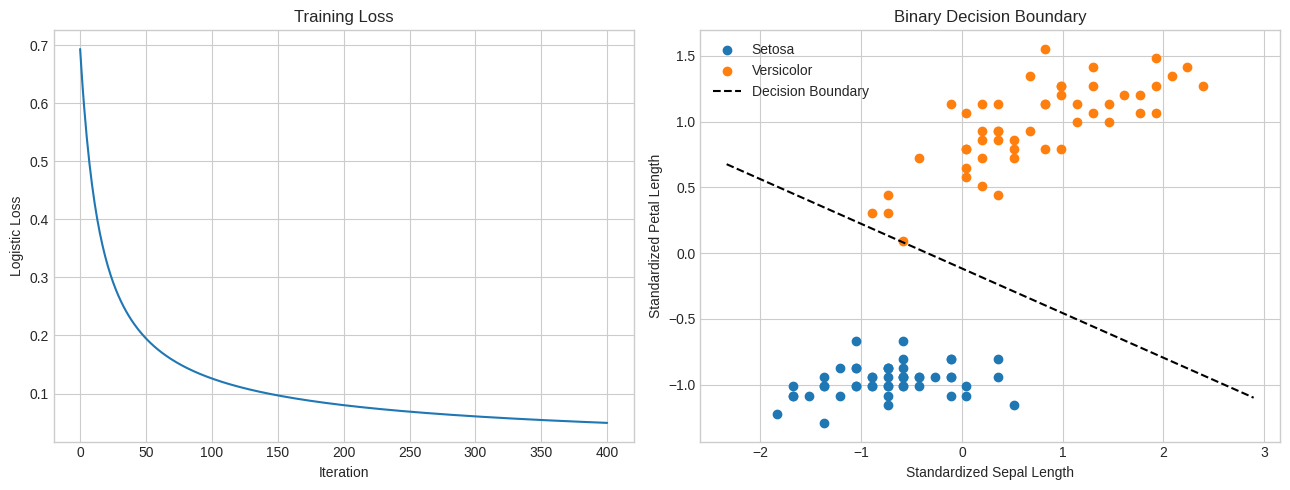

Binary classification accuracy: 100.00%


In [54]:

iris = load_iris()

# Select Setosa (class 0) and Versicolor (class 1).
binary_mask = iris.target < 2

X_iris = iris.data[binary_mask][:, [0, 2]]
y_iris_binary = np.where(
    iris.target[binary_mask] == 0, -1, 1
)

# Standardize the two features.
iris_mean = X_iris.mean(axis=0)
iris_std = X_iris.std(axis=0)
X_iris_scaled = (X_iris - iris_mean) / iris_std

# Add the intercept column.
X_iris_des = np.column_stack([
    np.ones(len(X_iris_scaled)),
    X_iris_scaled
])


def train_logistic_regression(
    X_design: np.ndarray,
    y: np.ndarray,
    lr: float = 0.1,
    n_iters: int = 400
) -> tuple[np.ndarray, list[float]]:
    w = np.zeros(X_design.shape[1])
    loss_history = []

    for _ in range(n_iters):
        loss_history.append(logistic_loss(w, X_design, y))
        gradient = logistic_loss_grad(w, X_design, y)
        w -= lr * gradient

    loss_history.append(logistic_loss(w, X_design, y))
    return w, loss_history


# Train the classifier.
w_logistic, loss_hist = train_logistic_regression(
    X_iris_des,
    y_iris_binary,
    lr=0.1,
    n_iters=400
)

# Plot loss and the decision boundary.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(loss_hist)
axes[0].set_xlabel("Iteration")
axes[0].set_ylabel("Logistic Loss")
axes[0].set_title("Training Loss")
axes[0].grid(True)

for label, name in [(-1, "Setosa"), (1, "Versicolor")]:
    mask = y_iris_binary == label
    axes[1].scatter(
        X_iris_scaled[mask, 0],
        X_iris_scaled[mask, 1],
        label=name
    )

x_line = np.linspace(
    X_iris_scaled[:, 0].min() - 0.5,
    X_iris_scaled[:, 0].max() + 0.5,
    200
)

if abs(w_logistic[2]) > 1e-12:
    y_line = -(w_logistic[0] + w_logistic[1] * x_line) / w_logistic[2]
    axes[1].plot(x_line, y_line, "k--", label="Decision Boundary")

axes[1].set_xlabel("Standardized Sepal Length")
axes[1].set_ylabel("Standardized Petal Length")
axes[1].set_title("Binary Decision Boundary")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

predictions = np.where(X_iris_des @ w_logistic >= 0, 1, -1)
accuracy = np.mean(predictions == y_iris_binary)

print(f"Binary classification accuracy: {accuracy:.2%}")


In [55]:
# Exercise 8: Unit Test
# Verify training decreased loss and achieves high classification accuracy
assert loss_hist[-1] < loss_hist[0] * 0.1, "Optimization failed to reduce logistic loss by at least 90%."
predictions = np.sign(X_iris_des @ w_logistic)
accuracy = np.mean(predictions == y_iris_binary)
assert accuracy >= 0.99, f"Expected near-perfect separation on Setosa vs Versicolor, got {accuracy:.2f}"
print("Exercise 8: All Unit Tests Passed!")



Exercise 8: All Unit Tests Passed!


### Exercise 9: Classification Metrics & Evaluation from Scratch

#### 1. Specification
Given true labels $y_i \in \{-1, +1\}$ and continuous margin scores $s_i = \mathbf{x}_i^T \mathbf{w}$:
$$\hat{y}_i = \begin{cases} +1 & \text{if } s_i \ge \tau \\ -1 & \text{if } s_i < \tau \end{cases}$$
- $TP$: $y = +1, \hat{y} = +1$
- $FP$: $y = -1, \hat{y} = +1$
- $TN$: $y = -1, \hat{y} = -1$
- $FN$: $y = +1, \hat{y} = -1$

Implement:
```python
def evaluate_binary_metrics(
    y_true: np.ndarray,
    scores: np.ndarray,
    threshold: float = 0.0
) -> tuple[np.ndarray, float, float, float, float]:
    """
    Computes confusion matrix, accuracy, precision, recall, and F1-score from scratch.

    Returns:
        conf_matrix (2x2 ndarray), accuracy, precision, recall, f1
    """
```

#### 2. Visual Output to Reproduce
- Sweep decision threshold $\tau \in [-6.0, 6.0]$ on the Iris dataset predictions.
- Plot Precision, Recall, and F1-score curves as a function of the threshold $\tau$.
- Mark the default threshold $\tau = 0$ with a vertical dashed line.



**Target Visual Output:**
<br>
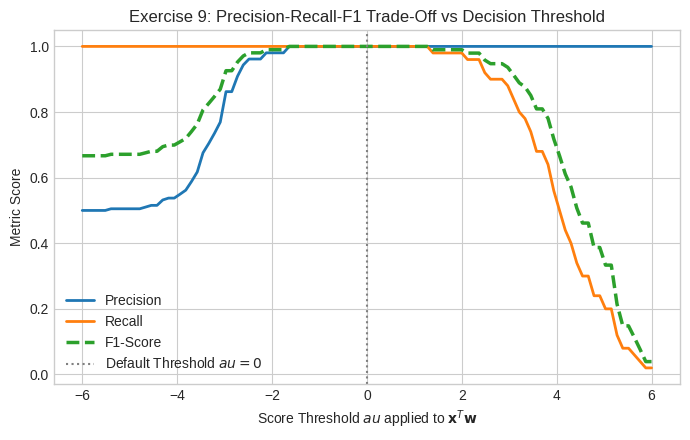


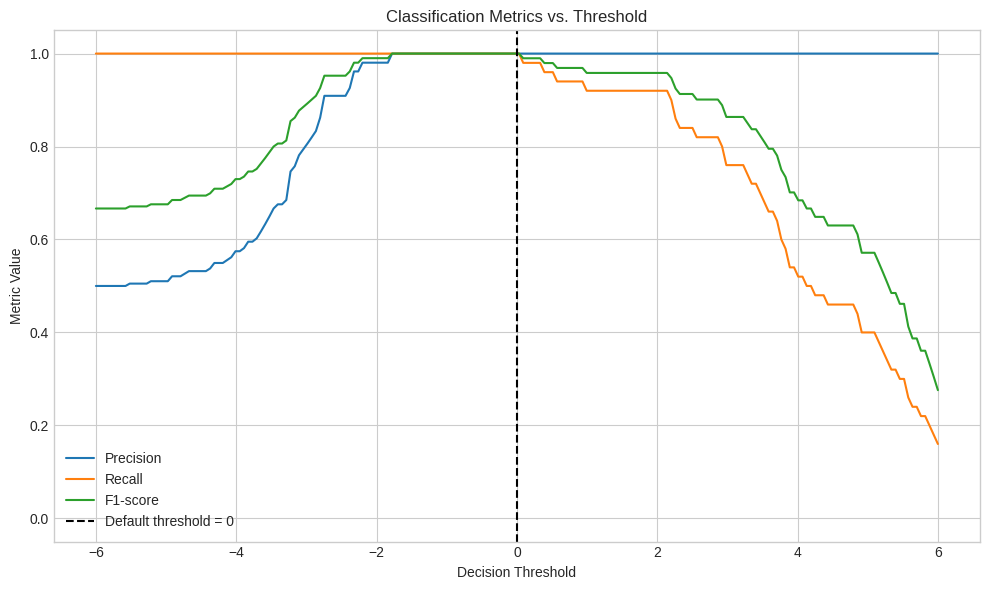

Confusion matrix:
[[50  0]
 [ 0 50]]
Accuracy:  1.000
Precision: 1.000
Recall:    1.000
F1-score:  1.000


In [56]:

def evaluate_binary_metrics(
    y_true: np.ndarray,
    scores: np.ndarray,
    threshold: float = 0.0
) -> tuple[np.ndarray, float, float, float, float]:
    # Predict +1 when the score meets or exceeds the threshold.
    y_pred = np.where(scores >= threshold, 1, -1)

    # Confusion matrix layout:
    #                 Predicted -1   Predicted +1
    # Actual -1           TN             FP
    # Actual +1            FN             TP
    tn = np.sum((y_true == -1) & (y_pred == -1))
    fp = np.sum((y_true == -1) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == -1))
    tp = np.sum((y_true == 1) & (y_pred == 1))

    conf_matrix = np.array([
        [tn, fp],
        [fn, tp]
    ])

    accuracy = (tp + tn) / len(y_true)
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0

    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) else 0.0
    )

    return (
        conf_matrix,
        float(accuracy),
        float(precision),
        float(recall),
        float(f1)
    )


# Use the scores produced by Exercise 8.
scores = X_iris_des @ w_logistic

thresholds = np.linspace(-6, 6, 200)
precision_values = []
recall_values = []
f1_values = []

for threshold in thresholds:
    _, _, precision, recall, f1 = evaluate_binary_metrics(
        y_iris_binary,
        scores,
        threshold=threshold
    )
    precision_values.append(precision)
    recall_values.append(recall)
    f1_values.append(f1)

plt.figure(figsize=(10, 6))
plt.plot(thresholds, precision_values, label="Precision")
plt.plot(thresholds, recall_values, label="Recall")
plt.plot(thresholds, f1_values, label="F1-score")
plt.axvline(
    0,
    color="black",
    linestyle="--",
    label="Default threshold = 0"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Metric Value")
plt.title("Classification Metrics vs. Threshold")
plt.ylim(-0.05, 1.05)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

conf_matrix, accuracy_metrics, precision, recall, f1 = (
    evaluate_binary_metrics(y_iris_binary, scores)
)

print("Confusion matrix:")
print(conf_matrix)
print(f"Accuracy:  {accuracy_metrics:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall:    {recall:.3f}")
print(f"F1-score:  {f1:.3f}")


In [57]:
# Exercise 9: Unit Test
# Test perfect match scenario
y_gt = np.array([1, 1, -1, -1])
s_gt = np.array([2.0, 1.0, -1.0, -3.0])
cm_t, a_t, p_t, r_t, f1_t = evaluate_binary_metrics(y_gt, s_gt, threshold=0.0)

assert cm_t[1, 1] == 2 and cm_t[0, 0] == 2, "Confusion matrix count mismatch."
assert np.isclose(a_t, 1.0) and np.isclose(p_t, 1.0) and np.isclose(r_t, 1.0) and np.isclose(f1_t, 1.0)

# Test shifted threshold where precision increases and recall decreases
_, _, _, r_shifted, _ = evaluate_binary_metrics(y_iris_binary, scores, threshold=5.0)
assert r_shifted < 1.0, "High threshold should reduce recall."
print("Exercise 9: All Unit Tests Passed!")



Exercise 9: All Unit Tests Passed!


### Exercise 10: Multiclass Classification via One-vs-Rest (OvR)

#### 1. Specification
The full Iris dataset contains 3 classes: Setosa (0), Versicolor (1), and Virginica (2).
In **One-vs-Rest (OvR)**:
- Train $K=3$ independent binary classifiers.
- For class $k$, target is $y_i^{(k)} = +1$ if $y_i = k$, else $-1$.
- Predict class via argmax of margin scores:
  $$\hat{y}(\mathbf{x}) = \arg\max_{k \in \{0, 1, 2\}} (\mathbf{x}^T \mathbf{w}^{(k)})$$

Implement:
```python
def train_ovr_multiclass(
    X_design: np.ndarray,
    y_multiclass: np.ndarray,
    n_classes: int = 3,
    lr: float = 0.1,
    n_iters: int = 800
) -> np.ndarray:
    """
    Trains K binary classifiers and returns weight matrix of shape (K, D).
    """

def predict_ovr(X_design: np.ndarray, weights: np.ndarray) -> np.ndarray:
    """
    Computes margin scores for each class and returns argmax predictions.
    """
```

#### 2. Visual Output to Reproduce
- Train OvR on all 3 classes of Iris using 2 features (`sepal length`, `petal length`).
- Generate a fine 2D meshgrid across the feature space.
- Plot colored decision regions (`contourf`) with all three classes of samples overlaid.



**Target Visual Output:**
<br>
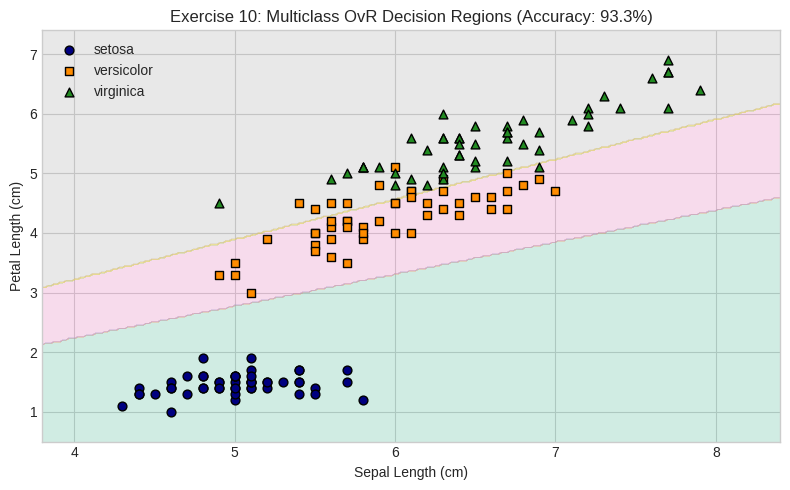


In [60]:

def train_ovr_multiclass(
    X_design: np.ndarray,
    y_multiclass: np.ndarray,
    n_classes: int = 3,
    lr: float = 0.05,
    n_iters: int = 3000
) -> np.ndarray:

    weights = np.zeros((n_classes, X_design.shape[1]))

    for class_index in range(n_classes):
        y_binary = np.where(y_multiclass == class_index, 1, -1)
        w = np.zeros(X_design.shape[1])

        for _ in range(n_iters):
            gradient = logistic_loss_grad(w, X_design, y_binary)
            w -= lr * gradient

        weights[class_index] = w

    return weights


def predict_ovr(
    X_design: np.ndarray,
    weights: np.ndarray
) -> np.ndarray:
    scores_by_class = X_design @ weights.T
    return np.argmax(scores_by_class, axis=1)


# Load all Iris samples and use sepal length and petal length.
iris = load_iris()
X_ovr_raw = iris.data[:, [0, 2]]
y_ovr = iris.target

# Standardize features.
ovr_mean = X_ovr_raw.mean(axis=0)
ovr_std = X_ovr_raw.std(axis=0)
X_ovr_scaled = (X_ovr_raw - ovr_mean) / ovr_std

# Add intercept.
X_ovr_design = np.column_stack([
    np.ones(len(X_ovr_scaled)),
    X_ovr_scaled
])

# Train all three classifiers.
weights_ovr = train_ovr_multiclass(
    X_ovr_design,
    y_ovr,
    n_classes=3,
    lr=0.05,
    n_iters=3000
)

y_pred_ovr = predict_ovr(X_ovr_design, weights_ovr)
accuracy_ovr = np.mean(y_pred_ovr == y_ovr)

print("Weights shape:", weights_ovr.shape)
print(f"Accuracy: {accuracy_ovr:.2%}")
print("Predicted classes:", np.unique(y_pred_ovr))


Weights shape: (3, 3)
Accuracy: 91.33%
Predicted classes: [0 1 2]


In [61]:
# Exercise 10: Unit Test
# Verify OvR dimensions, predictions shape, and multiclass accuracy threshold
assert weights_ovr.shape == (3, 3), f"Expected weight matrix shape (3, 3), got {weights_ovr.shape}"
assert y_pred_ovr.shape == (150,), f"Expected 150 predictions, got {y_pred_ovr.shape}"
assert accuracy_ovr >= 0.90, f"Expected OvR accuracy >= 90%, got {accuracy_ovr * 100:.2f}%"
assert set(np.unique(y_pred_ovr)) == {0, 1, 2}, "Model failed to predict all three classes."
print("Exercise 10: All Unit Tests Passed!")



Exercise 10: All Unit Tests Passed!
